# Deliverable 1

### Task 1: 
Sources used for 1
    - https://frost.met.no/python_example.html
    - Week 5 lecture

In [130]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [131]:
client_id = open("../frost_id/client_id.txt").read()

# Dates to get data from
dates = {
    1925: "1925-01-01/1925-12-31",
    2025: "2025-01-01/2025-12-31"
}

# A dictionary to store data by year(dates)
frost_payloads = {}

endpoint = "https://frost.met.no/observations/v0.jsonld"

# Looping through the dates dict to reduce code replication for task 3
for year, reference_time in dates.items():
    
    # Week 5 lecture have been used for the code inside this loop
    parameters = {
        "sources": "SN17850",
        "elements": "mean(air_temperature P1D)",
        "referencetime": reference_time
    }

    r = requests.get(endpoint,parameters,auth=(client_id, ""))

    assert r.status_code == 200
    frost_payloads[year] = r.json()

data_1925 = frost_payloads[1925]["data"]
data_2025 = frost_payloads[2025]["data"]

In [132]:
# Converts list into dataframe and sets the time as index
# Again doing it with a loop to handle both 2025 and 1925 in same code block
# Week 5 lecture have been used for the code inside the loop 

temperature_data = {}

for year, payload in frost_payloads.items():
    temp_data = [
        {
            "Time": pd.to_datetime(entry["referenceTime"]),
            "T_avg": entry["observations"][0]["value"]
        }
        for entry in payload["data"]
        ]
    
    temperature_data[year] = (pd.DataFrame(temp_data).set_index("Time"))

df_1925 = temperature_data[1925]
df_2025 = temperature_data[2025]

##### Plotting of mean air temperature

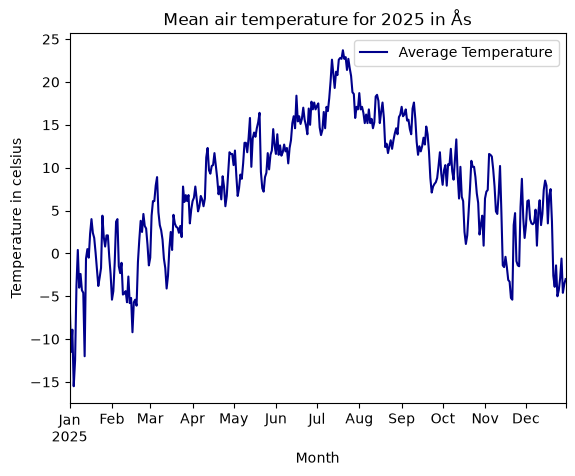

In [141]:
plot_of_2025 = df_2025.plot(
    y="T_avg",
    kind="line",
    color="darkblue",
    label="Average Temperature",
    title=("Mean air temperature for 2025 in Ås"),
    xlabel=("Month"),
    ylabel=("Temperature in celsius")
    )

plt.minorticks_off() # Only showing monthly ticks
plt.show()

##### Discussion of plot:
For the first plot we've decided to use a line plot, simply because it is the most informative when looking at time series data of temperature.
A dark blue color have been chosen for high contrast. By using .minorticks_off() we've removed ticks that was difficult to see what was pointing to, only leaving us with ticks for each month. Otherwise, labels and titles have been named to give information about what the plot is about.

From the plot we can see that the highest average temperatures are in july and the coldes month january/february.



Summary table of temperature

In [134]:
summary_table = pd.DataFrame({
    "mean": T_data.mean(),
    "median": T_data.median(),
    "min": T_data.min(),
    "max": T_data.max()
    }).round(1)

# Rename T_avg
summary_table.index = ["Temperature (°C)"]

print(f"Average temperatures in Ås, 2025\n {'_' * 50}")
print(summary_table)

Average temperatures in Ås, 2025
 __________________________________________________
                  mean  median   min   max
Temperature (°C)   7.9     8.4 -15.5  23.7


##### Discussion of summary table:
Here we've made a data frame for the summary table, then found statistics by using corresponding statistic methods. We've decided using round to get all the statistics neat and similiar in decimals. 
From the statistics we get the yearly mean of 7.9 celsius, and the median is not too far off meaning we dont have outliers "breaking" the mean stat. (But would be more correctly to use median when describing this data without deeper statistical analysis)

### Task 2

### Task 3

##### Plot of mean temperatures in 1925 and 2025
The 1925 temperatures have been retrieved earlier in the code (inside the loops in task 1).
This was done to reduce code duplication, therefore only plot and summary table will be shown in this section. 

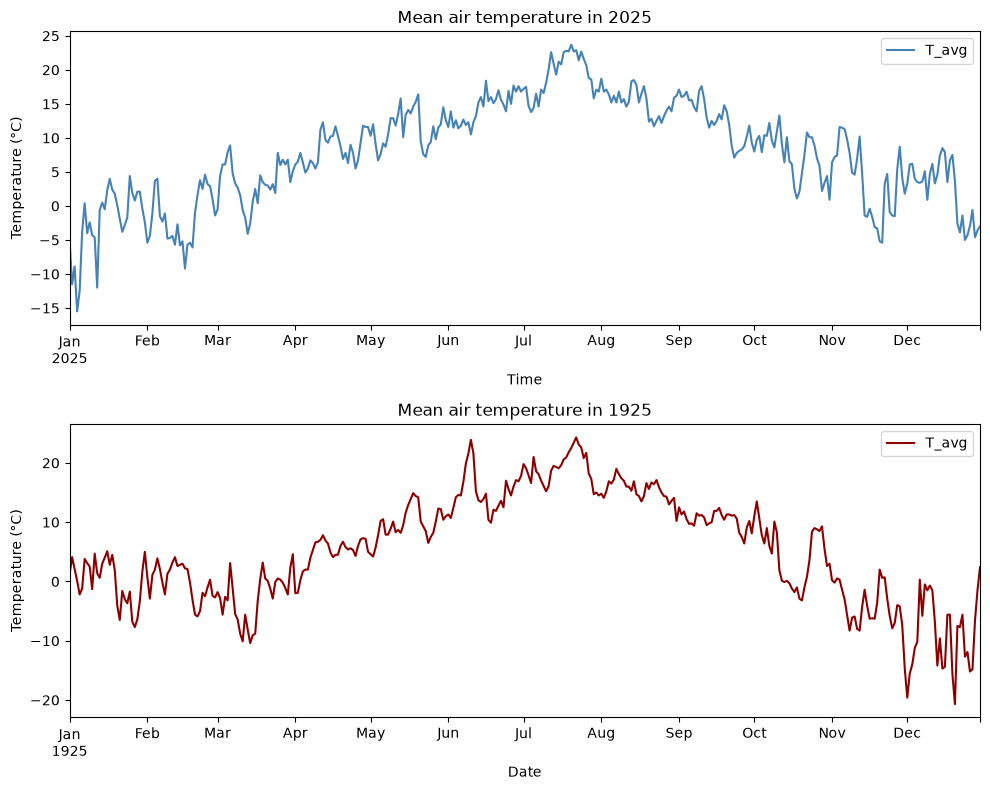

In [165]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

df_2025.plot(y="T_avg", kind="line", color="steelblue", ax=axes[0])
axes[0].set_title("Mean air temperature in 2025")
axes[0].set_ylabel("Temperature (°C)")
axes[0].minorticks_off()

df_1925.plot(y="T_avg", kind="line", color="darkred", ax=axes[1])
axes[1].set_title("Mean air temperature in 1925")
axes[1].set_ylabel("Temperature (°C)")
axes[1].set_xlabel("Date")
axes[1].minorticks_off()

fig.tight_layout()
plt.show()

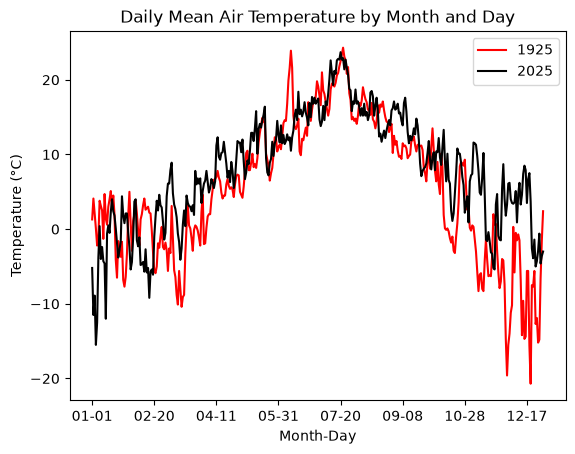

In [ ]:
s_1925 = df_1925["T_avg"].copy()
s_2025 = df_2025["T_avg"].copy()

s_1925.index = df_1925.index.strftime("%m-%d")
s_2025.index = df_2025.index.strftime("%m-%d")

ax = s_1925.plot(color="red", label="1925")
s_2025.plot(ax=ax, color="black", label="2025")

ax.set_title("Daily Mean Air Temperature by Month and Day")
ax.set_xlabel("Month-Day")
ax.set_ylabel("Temperature (°C)")
ax.legend()
plt.show()